<div style="background:#080c10;padding:22px 26px;border-radius:10px;border-left:4px solid #00d4ff">
<h1 style="color:#00d4ff;margin:0 0 8px 0">MLB Opening &amp; Closing Odds, US Books — Verify before you buy</h1>
<p style="color:#e6edf3;margin:0;font-size:15px">The figures of the listing and of its README, recomputed from the file of the
full product: 18,242 MLB games from the 2019 season to the 2026 World Series, opening and closing prices from FanDuel,
DraftKings, BetMGM, Caesars, BetRivers, BetOnline, theScore, Fanatics, Hard Rock, Pinnacle, Bet365, Kalshi and Polymarket,
in American odds, each with the time it was recorded.</p>
</div>

This notebook runs on the **full product**, not on the sample. Each section states a claim of the listing or of the
README, recomputes it from the file and prints **PASS** or **FAIL**. The expected values are written in plain sight in
the `CLAIMS` cell and next to the checks of the listing's images; everything else is read from the data. Only what the
file cannot show is not recomputed: the counts of prices left out while it was built.

⚾ **[→ The full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/vjrnqv?utm_source=github&utm_medium=notebook&utm_campaign=mlb_us&utm_content=notebook_top)** · also on [Whop](https://whop.com/oliviersportsdata/mlb-opening-closing-odds-9-us-books-pinnacle-2019-2026/?utm_source=github&utm_medium=notebook&utm_campaign=mlb_us&utm_content=whop_top) · free 26-game sample: same layout, same 294 columns.

In [1]:
import os, glob, zipfile, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
NAME = "MLB_Opening_Closing_Odds_2019-2026"

def find_csv():
    """The CSV of the full product (the largest match wins: sample and full may both be attached), or the CSV inside the ZIP."""
    hits = []
    for base in (os.environ.get("MLB_ROOT", ""), "/kaggle/input", "."):
        if base and os.path.isdir(base):
            hits += [p for p in glob.glob(os.path.join(base, "**", NAME + "*.csv"), recursive=True) if os.path.isfile(p)]
            hits += [p for p in glob.glob(os.path.join(base, "**", NAME + "*.zip"), recursive=True) if os.path.isfile(p)]
    if not hits:
        raise FileNotFoundError(NAME + ".csv not found: attach the full dataset to this notebook")
    return max(hits, key=os.path.getsize)

PATH = find_csv()
if PATH.endswith(".zip"):
    data = zipfile.ZipFile(PATH).read(NAME + ".csv")
    RAW = pd.read_csv(io.BytesIO(data), dtype=str, keep_default_na=False)
    F = pd.read_csv(io.BytesIO(data), low_memory=False)
else:
    RAW = pd.read_csv(PATH, dtype=str, keep_default_na=False)      # every cell exactly as written in the file
    F = pd.read_csv(PATH, low_memory=False)                          # the same file, numbers parsed
print(f"{os.path.basename(PATH)}  ·  {len(F):,} rows  ·  {F.shape[1]} columns")

RESULTS = []
def check(label, ok, detail=""):
    RESULTS.append((label, bool(ok)))
    print(("PASS  " if ok else "FAIL  ") + label + (f"   [{detail}]" if detail != "" else ""))

SOURCES = ["Pinnacle", "Bet365", "FanDuel", "DraftKings", "BetMGM", "Caesars", "BetRivers", "BetOnline", "theScore",
           "Fanatics", "HardRock", "Kalshi", "Polymarket"]
BOOKS = SOURCES[:11]
START = pd.to_datetime(RAW["Kickoff_UTC"])
EPOCH0 = pd.Timestamp("1970-01-01", tz="UTC")
def has(col): return RAW[col] != ""
def mins(col): return (pd.to_datetime(RAW[col].where(has(col))) - START).dt.total_seconds() / 60
def first_day(mask): return RAW.loc[mask, "Game_ID"].str[:8].min()
def any_close(s): return has(f"{s}_ML_Close_Time") | has(f"{s}_Spread_Close_Time") | has(f"{s}_Total_Close_Time")
def share(mask, sel): return int(100 * mask[sel].mean())          # rounded down, as in the README

MLB_Opening_Closing_Odds_2019-2026.csv  ·  18,242 rows  ·  294 columns


## The claims
The expected values, copied from the README in the ZIP and from the listings.

In [2]:
CLAIMS = {
    # README and listing: the file
    "games": 18242, "seasons": 8, "columns": 294, "prices": 1530594,
    "first_day": "20190320", "last_day": "20261028",
    "games_by_season": {"2019": 2466, "2020": 951, "2021": 2466, "2022": 2470, "2023": 2471, "2024": 2472, "2025": 2477, "2026": 2469},
    "playoff_games_by_season": {"2019": 37, "2020": 53, "2021": 37, "2022": 40, "2023": 41, "2024": 43, "2025": 47, "2026": 40},
    "stages": {"Regular Season": 17904, "Playoffs": 338}, "endings": {"Regulation": 16614, "Extra Innings": 1588, "Shortened": 40},
    "neutral_site": 107, "neutral_site_2020_postseason": 35, "doubleheader_games": 672,
    "seven_inning_games": {"2020": 111, "2021": 121}, "mean_closing_total_7_vs_9": (6.75, 8.74),
    "games_with_a_probable_pitcher_missing": 23,
    "games_without_any_price": ["20190519_OAK_DET", "20190527_KC_CWS", "20190613_STL_NYM", "20190807_KC_BOS",
                                "20200805_BAL_MIA_2", "20200809_BAL_WSH"],
    # listing: first closing moneyline, source by source (official dates of the games)
    "first_close_ml": {"Bet365": "20190320", "FanDuel": "20190331", "DraftKings": "20190331", "BetRivers": "20190829",
                       "Pinnacle": "20200723", "BetMGM": "20200723", "Caesars": "20200723", "BetOnline": "20200723",
                       "theScore": "20240320", "HardRock": "20250318", "Fanatics": "20250808", "Kalshi": "20260325",
                       "Polymarket": "20260325"},
    # README "Said plainly" and listing "Read this before you buy"
    "pinnacle_close_ml_share_2020": 69, "close_ml_share_2019": {"FanDuel": 68, "DraftKings": 79, "BetRivers": 16},
    "open_ml_share_2019": {"FanDuel": 2, "DraftKings": 7},
    "closing_prices_2025": {"BetRivers": 613, "Fanatics": 103, "HardRock": 330},
    "fanatics_open_ml_share_2026": 43, "close_ml_share_2026_one_in_ten": {"HardRock": 9, "BetRivers": 9},
    "gap_2026": {"from": "20260831", "to": "20260912", "games": 173, "pinnacle": 7, "bet365": 172},
    "pinnacle_closing_totals_over_3h_before": {"2026": (590, 1874), "2025": 2},
    "kalshi_polymarket_same_close_2026": (1021, 2007),
    "team_totals_period": ("20210401", "20260831"), "open_without_close": 17300,
    # subscription listing: the 2026 season
    "min_close_ml_share_2026_core": 83, "close_ml_share_2026_prediction_markets": {"Kalshi": 82, "Polymarket": 84},
    # README: median closing time of the moneyline, minutes against the scheduled first pitch
    "ml_close_median_min": {"Pinnacle": -1, "Bet365": -1, "FanDuel": -9, "DraftKings": -9, "BetMGM": -9, "Caesars": -9,
                            "BetRivers": -45, "BetOnline": -6, "theScore": -9, "Fanatics": -120, "HardRock": -4,
                            "Kalshi": -4, "Polymarket": -4},
}

## 1. The file
Games, seasons, stages, endings, ballparks, doubleheaders, columns and prices.

In [3]:
check("games", len(RAW) == CLAIMS["games"], len(RAW))
check("columns", RAW.shape[1] == CLAIMS["columns"], RAW.shape[1])
check("seasons", RAW["Season"].nunique() == CLAIMS["seasons"], sorted(RAW["Season"].unique()))
check("one row per game", RAW["Game_ID"].is_unique and RAW["MLB_Game_PK"].is_unique)
day = RAW["Game_ID"].str[:8]
check("first and last day (official dates): 20 March 2019, 28 October 2026", (day.min(), day.max()) == (CLAIMS["first_day"], CLAIMS["last_day"]), (day.min(), day.max()))
check("games by season", RAW["Season"].value_counts().to_dict() == CLAIMS["games_by_season"], RAW["Season"].value_counts().sort_index().to_dict())
po = RAW["Stage"] == "Playoffs"
check("postseason games by season", RAW.loc[po, "Season"].value_counts().to_dict() == CLAIMS["playoff_games_by_season"])
check("stages", RAW["Stage"].value_counts().to_dict() == CLAIMS["stages"], RAW["Stage"].value_counts().to_dict())
check("endings", RAW["Match_Ending"].value_counts().to_dict() == CLAIMS["endings"], RAW["Match_Ending"].value_counts().to_dict())
neutral = RAW["Neutral_Site"] == "Yes"
check("107 neutral-site games, 35 of them the 2020 postseason",
      (int(neutral.sum()), int((neutral & po & (RAW["Season"] == "2020")).sum())) == (CLAIMS["neutral_site"], CLAIMS["neutral_site_2020_postseason"]))
check("doubleheader games", (RAW["Doubleheader"] == "Yes").sum() == CLAIMS["doubleheader_games"])
seven = RAW["Scheduled_Innings"] == "7"
check("7-inning games: 111 in 2020, 121 in 2021", RAW.loc[seven, "Season"].value_counts().to_dict() == CLAIMS["seven_inning_games"])
tot_cols = [f"{b}_Total_Line_Close" for b in BOOKS]
y2021 = RAW["Season"].isin(["2020", "2021"])
m7 = pd.concat([F.loc[seven & y2021, c] for c in tot_cols]).dropna().mean()
m9 = pd.concat([F.loc[~seven & y2021, c] for c in tot_cols]).dropna().mean()
check("mean closing total: 6.75 on 7-inning games, 8.74 on the 9-inning games of 2020 and 2021",
      (round(float(m7), 2), round(float(m9), 2)) == CLAIMS["mean_closing_total_7_vs_9"], (round(float(m7), 2), round(float(m9), 2)))
miss = (RAW["Home_Probable_Pitcher"] == "") | (RAW["Away_Probable_Pitcher"] == "")
check("probable pitchers: one missing on 23 games", miss.sum() == CLAIMS["games_with_a_probable_pitcher_missing"], int(miss.sum()))
price_cols = [c for c in RAW.columns if c.split("_")[0] in SOURCES and not c.endswith("_Time") and "_Line_" not in c]
n_prices = int((RAW[price_cols] != "").sum().sum())
check("prices", n_prices == CLAIMS["prices"], f"{n_prices:,}")
no_price = sorted(RAW.loc[~(RAW[price_cols] != "").any(axis=1), "Game_ID"])
check("6 games have no price at all", no_price == CLAIMS["games_without_any_price"], no_price)
per_source = {s: sum(c.startswith(s + "_") for c in RAW.columns) for s in SOURCES}
check("22 columns per book, 38 for Pinnacle, 6 for Kalshi and Polymarket",
      per_source == {**{s: 22 for s in BOOKS}, "Pinnacle": 38, "Kalshi": 6, "Polymarket": 6}, per_source)

PASS  games   [18242]
PASS  columns   [294]
PASS  seasons   [['2019', '2020', '2021', '2022', '2023', '2024', '2025', '2026']]
PASS  one row per game
PASS  first and last day (official dates): 20 March 2019, 28 October 2026   [('20190320', '20261028')]
PASS  games by season   [{'2019': 2466, '2020': 951, '2021': 2466, '2022': 2470, '2023': 2471, '2024': 2472, '2025': 2477, '2026': 2469}]
PASS  postseason games by season
PASS  stages   [{'Regular Season': 17904, 'Playoffs': 338}]
PASS  endings   [{'Regulation': 16614, 'Extra Innings': 1588, 'Shortened': 40}]
PASS  107 neutral-site games, 35 of them the 2020 postseason
PASS  doubleheader games
PASS  7-inning games: 111 in 2020, 121 in 2021
PASS  mean closing total: 6.75 on 7-inning games, 8.74 on the 9-inning games of 2020 and 2021   [(6.75, 8.74)]
PASS  probable pitchers: one missing on 23 games   [23]
PASS  prices   [1,530,594]
PASS  6 games have no price at all   [['20190519_OAK_DET', '20190527_KC_CWS', '20190613_STL_NYM', '20190807_K

## 2. Scores
Final score, winner, total runs, margin, how the game ended.

In [4]:
hs, aw = F["Home_Score"], F["Away_Score"]
check("Total_Score = home + away", (F["Total_Score"] == hs + aw).all())
check("Margin = |home - away|", (F["Margin"] == (hs - aw).abs()).all())
check("Winner follows the score, never a tie", (F["Winner"] == np.where(hs > aw, "Home", "Away")).all() and (hs != aw).all())
ip, si = F["Innings_Played"], F["Scheduled_Innings"]
check("Match_Ending follows the innings: extra beyond the scheduled ones, shortened below them",
      (F["Match_Ending"] == np.where(ip > si, "Extra Innings", np.where(ip < si, "Shortened", "Regulation"))).all())

PASS  Total_Score = home + away
PASS  Margin = |home - away|
PASS  Winner follows the score, never a tie
PASS  Match_Ending follows the innings: extra beyond the scheduled ones, shortened below them


## 3. Each source, from when
The first closing moneyline of each source, as the listing states them.

In [5]:
for s, d in CLAIMS["first_close_ml"].items():
    got = first_day(has(f"{s}_ML_Home_Close"))
    check(f"{s}: first closing moneyline {d}", got == d, got)

PASS  Bet365: first closing moneyline 20190320   [20190320]
PASS  FanDuel: first closing moneyline 20190331   [20190331]
PASS  DraftKings: first closing moneyline 20190331   [20190331]
PASS  BetRivers: first closing moneyline 20190829   [20190829]
PASS  Pinnacle: first closing moneyline 20200723   [20200723]


PASS  BetMGM: first closing moneyline 20200723   [20200723]
PASS  Caesars: first closing moneyline 20200723   [20200723]
PASS  BetOnline: first closing moneyline 20200723   [20200723]
PASS  theScore: first closing moneyline 20240320   [20240320]
PASS  HardRock: first closing moneyline 20250318   [20250318]
PASS  Fanatics: first closing moneyline 20250808   [20250808]
PASS  Kalshi: first closing moneyline 20260325   [20260325]
PASS  Polymarket: first closing moneyline 20260325   [20260325]


## 4. The gaps, said plainly
Every limit stated in the README and the listing, recomputed.

In [6]:
y19, y20, y25, y26 = (RAW["Season"] == s for s in ("2019", "2020", "2025", "2026"))
check("Pinnacle: no price before the 2020 season, a closing moneyline on 69% of the 2020 games",
      not any_close("Pinnacle")[RAW["Season"] < "2020"].any() and share(has("Pinnacle_ML_Home_Close"), y20) == CLAIMS["pinnacle_close_ml_share_2020"])
got = {s: share(has(f"{s}_ML_Home_Close"), y19) for s in CLAIMS["close_ml_share_2019"]}
check("2019: closing moneyline on 68% (FanDuel), 79% (DraftKings) and 16% (BetRivers) of the games", got == CLAIMS["close_ml_share_2019"], got)
got = {s: share(has(f"{s}_ML_Home_Open"), y19) for s in CLAIMS["open_ml_share_2019"]}
check("2019: opening moneyline on 2% (FanDuel) and 7% (DraftKings) of the games", got == CLAIMS["open_ml_share_2019"], got)
check("BetMGM, Caesars and BetOnline start with the 2020 season, theScore on 20 March 2024",
      not (any_close("BetMGM") | any_close("Caesars") | any_close("BetOnline"))[RAW["Season"] < "2020"].any()
      and first_day(any_close("theScore")) == "20240320")
got = {s: int(sum(has(f"{s}_{m}_Close_Time")[y25].sum() for m in ("ML", "Spread", "Total"))) for s in CLAIMS["closing_prices_2025"]}
check("2025: few closing prices for BetRivers, Fanatics and Hard Rock (613, 103 and 330)", got == CLAIMS["closing_prices_2025"], got)
got = (share(has("Fanatics_ML_Home_Open"), y26), {s: share(has(f"{s}_ML_Home_Close"), y26) for s in ("HardRock", "BetRivers")})
check("2026: Fanatics opens 43% of the games; Hard Rock and BetRivers close about one game in ten",
      got == (CLAIMS["fanatics_open_ml_share_2026"], CLAIMS["close_ml_share_2026_one_in_ten"]), got)
g = CLAIMS["gap_2026"]
gap = RAW["Game_ID"].str[:8].between(g["from"], g["to"])
got = (int(gap.sum()), int((gap & has("Pinnacle_ML_Home_Close")).sum()), int((gap & has("Bet365_ML_Home_Close")).sum()))
check("31 August to 12 September 2026: 7 of the 173 games with a Pinnacle closing moneyline, 172 with Bet365's",
      got == (g["games"], g["pinnacle"], g["bet365"]), got)
old = mins("Pinnacle_Total_Close_Time") < -180
p26 = has("Pinnacle_Total_Close_Time") & y26
got = ((int((old & y26).sum()), int(p26.sum())), int((old & y25).sum()))
check("Pinnacle's closing total more than 3 hours before the first pitch: 590 of 1,874 in 2026, 2 in 2025",
      got == (CLAIMS["pinnacle_closing_totals_over_3h_before"]["2026"], CLAIMS["pinnacle_closing_totals_over_3h_before"]["2025"]), got)
both = y26 & has("Kalshi_ML_Home_Close") & has("Polymarket_ML_Home_Close")
same = both & (RAW["Kalshi_ML_Home_Close"] == RAW["Polymarket_ML_Home_Close"]) & (RAW["Kalshi_ML_Away_Close"] == RAW["Polymarket_ML_Away_Close"])
check("Kalshi and Polymarket identical at the close in 1,021 of 2,007 games", (int(same.sum()), int(both.sum())) == CLAIMS["kalshi_polymarket_same_close_2026"], (int(same.sum()), int(both.sum())))
check("Kalshi and Polymarket: closing prices from 25 March 2026, moneyline only",
      first_day(has("Kalshi_ML_Home_Close") | has("Polymarket_ML_Home_Close")) == "20260325"
      and not any(c.startswith(("Kalshi_Spread", "Kalshi_Total", "Polymarket_Spread", "Polymarket_Total")) for c in RAW.columns))
core = ["Pinnacle", "Bet365", "FanDuel", "DraftKings", "BetMGM", "Caesars", "BetOnline", "theScore"]
share26 = {s: share(has(f"{s}_ML_Home_Close"), y26) for s in core + ["Kalshi", "Polymarket"]}
check("2026: Pinnacle, Bet365 and 6 US books close the moneyline on at least 83% of the games, Kalshi 82%, Polymarket 84%",
      min(share26[s] for s in core) == CLAIMS["min_close_ml_share_2026_core"]
      and {s: share26[s] for s in ("Kalshi", "Polymarket")} == CLAIMS["close_ml_share_2026_prediction_markets"], share26)
tt = has("Pinnacle_Team_Total_Home_Close_Time") | has("Pinnacle_Team_Total_Away_Close_Time")
tt_any = tt | has("Pinnacle_Team_Total_Home_Open_Time") | has("Pinnacle_Team_Total_Away_Open_Time")
check("team totals: Pinnacle only, 1 April 2021 to 31 August 2026, none in 2020",
      (first_day(tt), RAW.loc[tt, "Game_ID"].str[:8].max()) == CLAIMS["team_totals_period"] and not tt_any[RAW["Season"] == "2020"].any()
      and not tt_any[RAW["Game_ID"].str[:8] > CLAIMS["team_totals_period"][1]].any())
blocks = [c[:-len("_Close_Time")] for c in RAW.columns if c.endswith("_Close_Time")]
n_open_only = sum(int((has(b + "_Open_Time") & ~has(b + "_Close_Time")).sum()) for b in blocks)
check("markets with an opening price and no closing price", n_open_only == CLAIMS["open_without_close"], n_open_only)
same_t = sum(int((has(b + "_Open_Time") & (RAW[b + "_Open_Time"] == RAW[b + "_Close_Time"])).sum()) for b in blocks)
check("an opening recorded at the same moment as the closing appears once, as the closing price", same_t == 0, same_t)
def whole(b, ph):
    cells = RAW[[c for c in RAW.columns if c.startswith(b + "_") and (c.endswith("_" + ph) or c == f"{b}_{ph}_Time")]] != ""
    return (cells.all(axis=1) | ~cells.any(axis=1)).all()
check("every price comes whole: both sides, its line and its time, or nothing", all(whole(b, ph) for b in blocks for ph in ("Open", "Close")))

PASS  Pinnacle: no price before the 2020 season, a closing moneyline on 69% of the 2020 games
PASS  2019: closing moneyline on 68% (FanDuel), 79% (DraftKings) and 16% (BetRivers) of the games   [{'FanDuel': 68, 'DraftKings': 79, 'BetRivers': 16}]
PASS  2019: opening moneyline on 2% (FanDuel) and 7% (DraftKings) of the games   [{'FanDuel': 2, 'DraftKings': 7}]
PASS  BetMGM, Caesars and BetOnline start with the 2020 season, theScore on 20 March 2024
PASS  2025: few closing prices for BetRivers, Fanatics and Hard Rock (613, 103 and 330)   [{'BetRivers': 613, 'Fanatics': 103, 'HardRock': 330}]
PASS  2026: Fanatics opens 43% of the games; Hard Rock and BetRivers close about one game in ten   [(43, {'HardRock': 9, 'BetRivers': 9})]
PASS  31 August to 12 September 2026: 7 of the 173 games with a Pinnacle closing moneyline, 172 with Bet365's   [(173, 7, 172)]
PASS  Pinnacle's closing total more than 3 hours before the first pitch: 590 of 1,874 in 2026, 2 in 2025   [((590, 1874), 2)]
PASS  Kals

PASS  markets with an opening price and no closing price   [17300]


PASS  an opening recorded at the same moment as the closing appears once, as the closing price   [0]


PASS  every price comes whole: both sides, its line and its time, or nothing


## 5. Closing and opening times
How close to the scheduled first pitch each price was recorded.

In [7]:
med = {s: mins(f"{s}_ML_Close_Time").median() for s in SOURCES}
for s, v in CLAIMS["ml_close_median_min"].items():
    nm = s.replace("HardRock", "Hard Rock")
    check(f"{nm}{chr(39) if nm.endswith('s') else chr(39) + 's'} closing moneyline: median {-v} min before the scheduled first pitch", round(med[s]) == v, round(float(med[s]), 1))
close_t = [c for c in RAW.columns if c.endswith("_Close_Time")]
open_t = [c for c in RAW.columns if c.endswith("_Open_Time")]
cm = pd.concat([mins(c) for c in close_t], axis=1)
om = pd.concat([mins(c) for c in open_t], axis=1)
check("no closing price older than 12 hours before the scheduled first pitch", cm.min().min() >= -720, round(float(cm.min().min())))
check("no closing price stamped more than 5 minutes after the scheduled first pitch", cm.max().max() <= 5, round(float(cm.max().max()), 1))
check("no opening price after the scheduled first pitch, none posted more than 15 days before",
      om.max().max() <= 0 and om.min().min() >= -15 * 1440, (round(float(om.max().max()), 1), round(float(om.min().min()) / 1440, 1)))
summary = pd.DataFrame({"median, minutes to first pitch": pd.Series(med).round(1),
                        "closing moneylines": [int(has(f"{s}_ML_Home_Close").sum()) for s in SOURCES]})
summary

PASS  Pinnacle's closing moneyline: median 1 min before the scheduled first pitch   [-0.6]
PASS  Bet365's closing moneyline: median 1 min before the scheduled first pitch   [-1.2]
PASS  FanDuel's closing moneyline: median 9 min before the scheduled first pitch   [-9.3]
PASS  DraftKings' closing moneyline: median 9 min before the scheduled first pitch   [-9.3]
PASS  BetMGM's closing moneyline: median 9 min before the scheduled first pitch   [-9.3]
PASS  Caesars' closing moneyline: median 9 min before the scheduled first pitch   [-9.3]
PASS  BetRivers' closing moneyline: median 45 min before the scheduled first pitch   [-45.0]
PASS  BetOnline's closing moneyline: median 6 min before the scheduled first pitch   [-6.4]
PASS  theScore's closing moneyline: median 9 min before the scheduled first pitch   [-9.3]
PASS  Fanatics' closing moneyline: median 120 min before the scheduled first pitch   [-119.9]
PASS  Hard Rock's closing moneyline: median 4 min before the scheduled first pitch   [-4.5

PASS  no closing price older than 12 hours before the scheduled first pitch   [-720]
PASS  no closing price stamped more than 5 minutes after the scheduled first pitch   [5.0]
PASS  no opening price after the scheduled first pitch, none posted more than 15 days before   [(0.0, -14.8)]


,"median, minutes to first pitch",closing moneylines
Pinnacle,-0.6,14292
Bet365,-1.2,17999
FanDuel,-9.3,16655
DraftKings,-9.3,17132
BetMGM,-9.3,14962
Caesars,-9.3,15040
BetRivers,-45.0,10380
BetOnline,-6.4,14348
theScore,-9.4,6925
Fanatics,-119.9,32


## 6. Markets and prices
American odds, ±1.5 run lines, half-run lines, margins within the stated bounds.

In [8]:
def prob(us):
    us = np.asarray(pd.to_numeric(us), dtype=float)
    neg = us < 0
    return np.where(neg, -us, 100.0) / np.where(neg, 100.0 - us, us + 100.0)
all_prices = RAW[price_cols].replace("", np.nan).stack().dropna()
check("American odds, written as integers of at least 100 in absolute value",
      all_prices.str.fullmatch(r"-?\d+").all() and (all_prices.astype(int).abs() >= 100).all())
lines = pd.concat([pd.to_numeric(RAW[c].replace("", np.nan)) for c in RAW.columns if "_Line_" in c]).dropna()
check("every line on a half run", ((lines * 2) % 1 == 0).all())
rl = pd.concat([pd.to_numeric(RAW[c].replace("", np.nan)) for c in RAW.columns if "_Spread_Home_Line_" in c]).dropna()
check("the run line is ±1.5 for every book", set(rl.unique()) == {-1.5, 1.5}, sorted(float(v) for v in rl.unique()))
over = []
for s in SOURCES:
    for ph in ("Open", "Close"):
        h, a = RAW[f"{s}_ML_Home_{ph}"], RAW[f"{s}_ML_Away_{ph}"]
        m = (h != "") & (a != "")
        mg = prob(h[m]) + prob(a[m]) - 1
        lo, hi = (0.015, 0.25) if ph == "Open" else (0.015, 0.10)
        if s in ("Kalshi", "Polymarket"):
            lo, hi = -1e-9, 0.07
        over.append(int(((mg < lo) | (mg > hi)).sum()))
check("moneyline margins within the stated bounds (books 1.5% to 25%, 10% at most at the close; Kalshi and Polymarket 0% to 7%)", sum(over) == 0, sum(over))
bad = 0
pairs = [(f"{s}_{mk}_{x}_{ph}", f"{s}_{mk}_{y}_{ph}") for s in BOOKS for mk, (x, y) in (("Spread", ("Home", "Away")), ("Total", ("Over", "Under"))) for ph in ("Open", "Close")]
pairs += [(f"Pinnacle_Team_Total_{t}_Over_{ph}", f"Pinnacle_Team_Total_{t}_Under_{ph}") for t in ("Home", "Away") for ph in ("Open", "Close")]
for a, b in pairs:
    m = (RAW[a] != "") & (RAW[b] != "")
    t = prob(RAW.loc[m, a]) + prob(RAW.loc[m, b])
    bad += int(((t < 1.0) | (t > 1.15)).sum())
check("run line, total and team total prices add up to 100%-115%", bad == 0, bad)
def side_max(key):
    cols = [c for c in RAW.columns if key in c and "_Line_" not in c and not c.endswith("_Time")]
    return pd.concat([RAW[c] for c in cols]).replace("", np.nan).dropna().astype(int).abs().max()
rl_max = side_max("_Spread_")
tot_max = max(side_max(k) for k in ("_Total_Over_", "_Total_Under_"))
check("run line prices within ±500, total and team total prices within ±300", rl_max <= 500 and tot_max <= 300, (int(rl_max), int(tot_max)))
t7 = pd.concat([F.loc[seven, c] for c in tot_cols]).dropna()
check("no 9-inning total on a 7-inning game (every closing total of those games below 9.5)", t7.max() < 9.5, float(t7.max()))

PASS  American odds, written as integers of at least 100 in absolute value


PASS  every line on a half run
PASS  the run line is ±1.5 for every book   [[-1.5, 1.5]]


PASS  moneyline margins within the stated bounds (books 1.5% to 25%, 10% at most at the close; Kalshi and Polymarket 0% to 7%)   [0]


PASS  run line, total and team total prices add up to 100%-115%   [0]
PASS  run line prices within ±500, total and team total prices within ±300   [(500, 278)]
PASS  no 9-inning total on a 7-inning game (every closing total of those games below 9.5)   [9.0]


## 7. The listing's images
Every value shown on the images of the listings, read back from the file.

In [9]:
IMAGES = {"file_1_home_ml_close_postseason_2026": {"20261011_LAD_MIL": ["-104", "-102", "-108", "-110", "-103", "-105", "-101", "100"], "20261015_MIL_LAD": ["-146", "-150", "-152", "-155", "-159", "-141", "-150", "-144"], "20261017_TB_CLE": ["100", "-102", "-103", "-105", "100", "-105", "-102", "100"], "20261023_TB_MIL": ["-182", "-184", "-189", "-190", "-190", "-179", "-183", "-178"], "20261026_MIL_TB": ["-110", "-116", "-115", "-118", "-120", "-109", "-112", "-108"], "20261027_MIL_TB": ["104", "104", "105", "100", "102", "111", "103", "108"], "20261028_MIL_TB": ["122", "122", "123", "120", "125", "126", "122", "127"]}, "file_2_one_game_13_sources": {"game": "20261027_MIL_TB", "score_away_home": [3, 4], "innings": 12, "home_ml_open_close": {"Pinnacle": ["124", "104"], "Bet365": ["111", "100"], "FanDuel": ["108", "104"], "DraftKings": ["103", "105"], "BetMGM": ["105", "100"], "Caesars": ["107", "102"], "BetRivers": ["104", "105"], "BetOnline": ["105", "103"], "theScore": ["105", "111"], "Fanatics": ["110", "100"], "HardRock": ["105", "100"], "Kalshi": ["104", "108"], "Polymarket": ["-104", "108"]}}, "cover_3_open_close_times": {"game": "20261028_MIL_TB", "score_away_home": [4, 1], "rows": {"Pinnacle": ["1.5", "-143", "2026-10-28T08:26:01Z", "1.5", "-151", "2026-10-28T23:59:43Z"], "Bet365": ["1.5", "-180", "2026-10-28T05:09:18Z", "1.5", "-165", "2026-10-28T23:48:48Z"], "FanDuel": ["1.5", "-156", "2026-10-28T06:05:00Z", "1.5", "-156", "2026-10-28T23:59:43Z"], "BetMGM": ["1.5", "-175", "2026-10-28T04:51:59Z", "1.5", "-150", "2026-10-28T23:59:43Z"], "Caesars": ["1.5", "-179", "2026-10-28T04:37:59Z", "1.5", "-152", "2026-10-28T23:59:43Z"]}}, "file_4_total_moves": {"date": "20250509", "rows": {"20250509_TEX_DET": ["7.5", "7", "7.5", "7", "1", "2", "3"], "20250509_ATL_PIT": ["8.5", "9", "8.5", "9", "2", "3", "5"], "20250509_PHI_CLE": ["8", "7.5", "7.5", "7.5", "0", "6", "6"], "20250509_CHC_NYM": ["7.5", "8", "7.5", "8", "2", "7", "9"], "20250509_MIA_CWS": ["8.5", "7.5", "7.5", "7.5", "2", "6", "8"], "20250509_CIN_HOU": ["8", "7.5", "7.5", "7.5", "0", "3", "3"], "20250509_SF_MIN": ["9", "8.5", "8.5", "8.5", "1", "3", "4"]}}, "file_5_prediction_markets": {"20260809_CIN_WSH": ["-118", "-114", "-108", "-113"], "20260809_ATH_BOS": ["-209", "-205", "-213", "-213"], "20260809_ATL_NYY": ["-137", "-138", "-138", "-138"], "20260809_TOR_PHI": ["-238", "-225", "-223", "-213"], "20260809_NYM_PIT": ["-133", "-142", "-133", "-138"], "20260809_LAA_MIA": ["-148", "-140", "-138", "-138"], "20260809_CLE_CWS": ["115", "116", "113", "117"]}, "sub_3_prediction_markets": {"20260809_CIN_WSH": ["-118", "-114", "-108", "-113"], "20260809_ATH_BOS": ["-209", "-205", "-213", "-213"], "20260809_ATL_NYY": ["-137", "-138", "-138", "-138"], "20260809_TOR_PHI": ["-238", "-225", "-223", "-213"], "20260809_NYM_PIT": ["-133", "-142", "-133", "-138"], "20260809_LAA_MIA": ["-148", "-140", "-138", "-138"], "20260809_CLE_CWS": ["115", "116", "113", "117"]}, "file_6_team_totals": {"date": "20250702", "rows": {"20250702_ATH_TB": ["3.5", "-109", "4.5", "-129", "5", "6", "Regulation"], "20250702_STL_PIT": ["4.5", "117", "3.5", "-105", "0", "5", "Regulation"], "20250702_SD_PHI_1": ["4.5", "-110", "4.5", "111", "6", "4", "Regulation"], "20250702_DET_WSH_1": ["4.5", "-123", "3.5", "-119", "11", "2", "Regulation"], "20250702_MIL_NYM_1": ["3.5", "-127", "3.5", "-139", "7", "2", "Regulation"], "20250702_SD_PHI_2": ["3.5", "101", "3.5", "-140", "1", "5", "Regulation"], "20250702_MIN_MIA": ["4.5", "106", "3.5", "-132", "2", "1", "Regulation"]}}, "file_7_coverage_ml_close": {"Pinnacle": {"first": "2020", "all_pct": 78.3, "pct_2026": 86.1}, "Bet365": {"first": "2019", "all_pct": 98.7, "pct_2026": 97.1}, "FanDuel": {"first": "2019", "all_pct": 91.3, "pct_2026": 84.0}, "DraftKings": {"first": "2019", "all_pct": 93.9, "pct_2026": 83.6}, "BetMGM": {"first": "2020", "all_pct": 82.0, "pct_2026": 84.7}, "Caesars": {"first": "2020", "all_pct": 82.4, "pct_2026": 83.9}, "BetRivers": {"first": "2019", "all_pct": 56.9, "pct_2026": 9.8}, "BetOnline": {"first": "2020", "all_pct": 78.7, "pct_2026": 84.1}, "theScore": {"first": "2024", "all_pct": 38.0, "pct_2026": 84.3}, "Fanatics": {"first": "2025", "all_pct": 0.2, "pct_2026": 0.4}, "HardRock": {"first": "2025", "all_pct": 1.3, "pct_2026": 9.2}, "Kalshi": {"first": "2026", "all_pct": 11.2, "pct_2026": 82.4}, "Polymarket": {"first": "2026", "all_pct": 11.5, "pct_2026": 84.6}}, "file_8_tiles": {"games": 18242, "seasons": 8, "sources": 13, "prices": 1530594, "columns": 294, "stages": {"Regular Season": 17904, "Playoffs": 338}, "endings": {"Regulation": 16614, "Extra Innings": 1588, "Shortened": 40}, "doubleheader_games": 672, "seven_inning_games": 232, "first_game": "20190320", "last_game": "20261028"}, "sub_1_home_ml_close": {"20260719_CWS_TOR": ["102", "102", "-109", "-102", "104"], "20260719_LAD_NYY_1": ["112", "110", "109", "110", "117"], "20260719_TEX_ATL": ["101", "100", "-103", "-102", "108"], "20260719_TB_BOS": ["-116", "-126", "-127", "-125", "-117"], "20260719_NYM_PHI": ["109", "108", "105", "105", "113"], "20260719_PIT_CLE": ["-109", "-110", "-114", "-115", "-108"]}, "sub_4_2026": {"games": 2469, "by_source": {"Pinnacle": 86.1, "Bet365": 97.1, "FanDuel": 84.0, "DraftKings": 83.6, "BetMGM": 84.7, "Caesars": 83.9, "BetRivers": 9.8, "BetOnline": 84.1, "theScore": 84.3, "Fanatics": 0.4, "HardRock": 9.2, "Kalshi": 82.4, "Polymarket": 84.6}}}
G = RAW.set_index("Game_ID")
x = IMAGES["file_1_home_ml_close_postseason_2026"]
check("image 1: home closing moneyline, 2026 postseason, League Championship Series to World Series",
      all([G.loc[g, f"{s}_ML_Home_Close"] for s in ["Pinnacle", "FanDuel", "DraftKings", "BetMGM", "Caesars", "theScore", "BetOnline", "Kalshi"]] == v for g, v in x.items()))
x = IMAGES["file_2_one_game_13_sources"]; r = G.loc[x["game"]]
check("image 2: Brewers at Rays, World Series game 4, 13 sources open and close, 12 innings",
      all([r[f"{s}_ML_Home_Open"], r[f"{s}_ML_Home_Close"]] == v for s, v in x["home_ml_open_close"].items())
      and len(x["home_ml_open_close"]) == 13 and [int(r["Away_Score"]), int(r["Home_Score"])] == x["score_away_home"] and int(r["Innings_Played"]) == x["innings"])
x = IMAGES["cover_3_open_close_times"]; r = G.loc[x["game"]]
check("image 3: opening and closing run lines with their times, Brewers at Rays, World Series game 5",
      all([r[f"{s}_Spread_Home_Line_Open"], r[f"{s}_Spread_Home_Open"], r[f"{s}_Spread_Open_Time"],
           r[f"{s}_Spread_Home_Line_Close"], r[f"{s}_Spread_Home_Close"], r[f"{s}_Spread_Close_Time"]] == v for s, v in x["rows"].items())
      and [int(r["Away_Score"]), int(r["Home_Score"])] == x["score_away_home"])
x = IMAGES["file_4_total_moves"]
check("image 4: totals of 9 May 2025, open to close",
      all([G.loc[g, c] for c in ("Pinnacle_Total_Line_Open", "Pinnacle_Total_Line_Close", "FanDuel_Total_Line_Close",
                                 "DraftKings_Total_Line_Close", "Away_Score", "Home_Score", "Total_Score")] == v for g, v in x["rows"].items()))
x = IMAGES["file_5_prediction_markets"]
check("image 5: Kalshi and Polymarket next to Pinnacle and FanDuel, 9 August 2026",
      all([G.loc[g, f"{s}_ML_Home_Close"] for s in ("Pinnacle", "FanDuel", "Kalshi", "Polymarket")] == v for g, v in x.items())
      and IMAGES["sub_3_prediction_markets"] == x)
x = IMAGES["file_6_team_totals"]
check("image 6: Pinnacle team totals, 2 July 2025",
      all([G.loc[g, c] for c in ("Pinnacle_Team_Total_Away_Line_Close", "Pinnacle_Team_Total_Away_Over_Close", "Pinnacle_Team_Total_Home_Line_Close",
                                 "Pinnacle_Team_Total_Home_Over_Close", "Away_Score", "Home_Score", "Match_Ending")] == v for g, v in x["rows"].items()))
x = IMAGES["file_7_coverage_ml_close"]
check("image 7: coverage of the closing moneyline, source by source",
      all((sorted(RAW.loc[has(f"{s}_ML_Home_Close"), "Season"].unique())[0] == v["first"]
           and round(100 * has(f"{s}_ML_Home_Close").mean(), 1) == v["all_pct"]
           and round(100 * has(f"{s}_ML_Home_Close")[y26].mean(), 1) == v["pct_2026"]) for s, v in x.items()))
x = IMAGES["file_8_tiles"]
check("image 8: games, seasons, sources, prices, columns, stages, endings, doubleheaders, 7-inning games, first and last game",
      (x["games"], x["seasons"], x["sources"], x["prices"], x["columns"]) == (len(RAW), RAW["Season"].nunique(), len(SOURCES), n_prices, RAW.shape[1])
      and x["stages"] == RAW["Stage"].value_counts().to_dict() and x["endings"] == RAW["Match_Ending"].value_counts().to_dict()
      and x["doubleheader_games"] == int((RAW["Doubleheader"] == "Yes").sum()) and x["seven_inning_games"] == int(seven.sum())
      and (x["first_game"], x["last_game"]) == (day.min(), day.max()))
x = IMAGES["sub_1_home_ml_close"]
check("subscription image 1: home closing moneyline, 19 July 2026",
      all([G.loc[g, f"{s}_ML_Home_Close"] for s in ["Pinnacle", "FanDuel", "DraftKings", "BetMGM", "Kalshi"]] == v for g, v in x.items()))
x = IMAGES["sub_4_2026"]
check("subscription image 4: the 2026 season, closing moneyline source by source",
      x["games"] == int(y26.sum()) and all(round(100 * has(f"{s}_ML_Home_Close")[y26].mean(), 1) == v for s, v in x["by_source"].items()))

PASS  image 1: home closing moneyline, 2026 postseason, League Championship Series to World Series
PASS  image 2: Brewers at Rays, World Series game 4, 13 sources open and close, 12 innings
PASS  image 3: opening and closing run lines with their times, Brewers at Rays, World Series game 5
PASS  image 4: totals of 9 May 2025, open to close
PASS  image 5: Kalshi and Polymarket next to Pinnacle and FanDuel, 9 August 2026
PASS  image 6: Pinnacle team totals, 2 July 2025


PASS  image 7: coverage of the closing moneyline, source by source
PASS  image 8: games, seasons, sources, prices, columns, stages, endings, doubleheaders, 7-inning games, first and last game
PASS  subscription image 1: home closing moneyline, 19 July 2026
PASS  subscription image 4: the 2026 season, closing moneyline source by source


## 8. Coverage at a glance

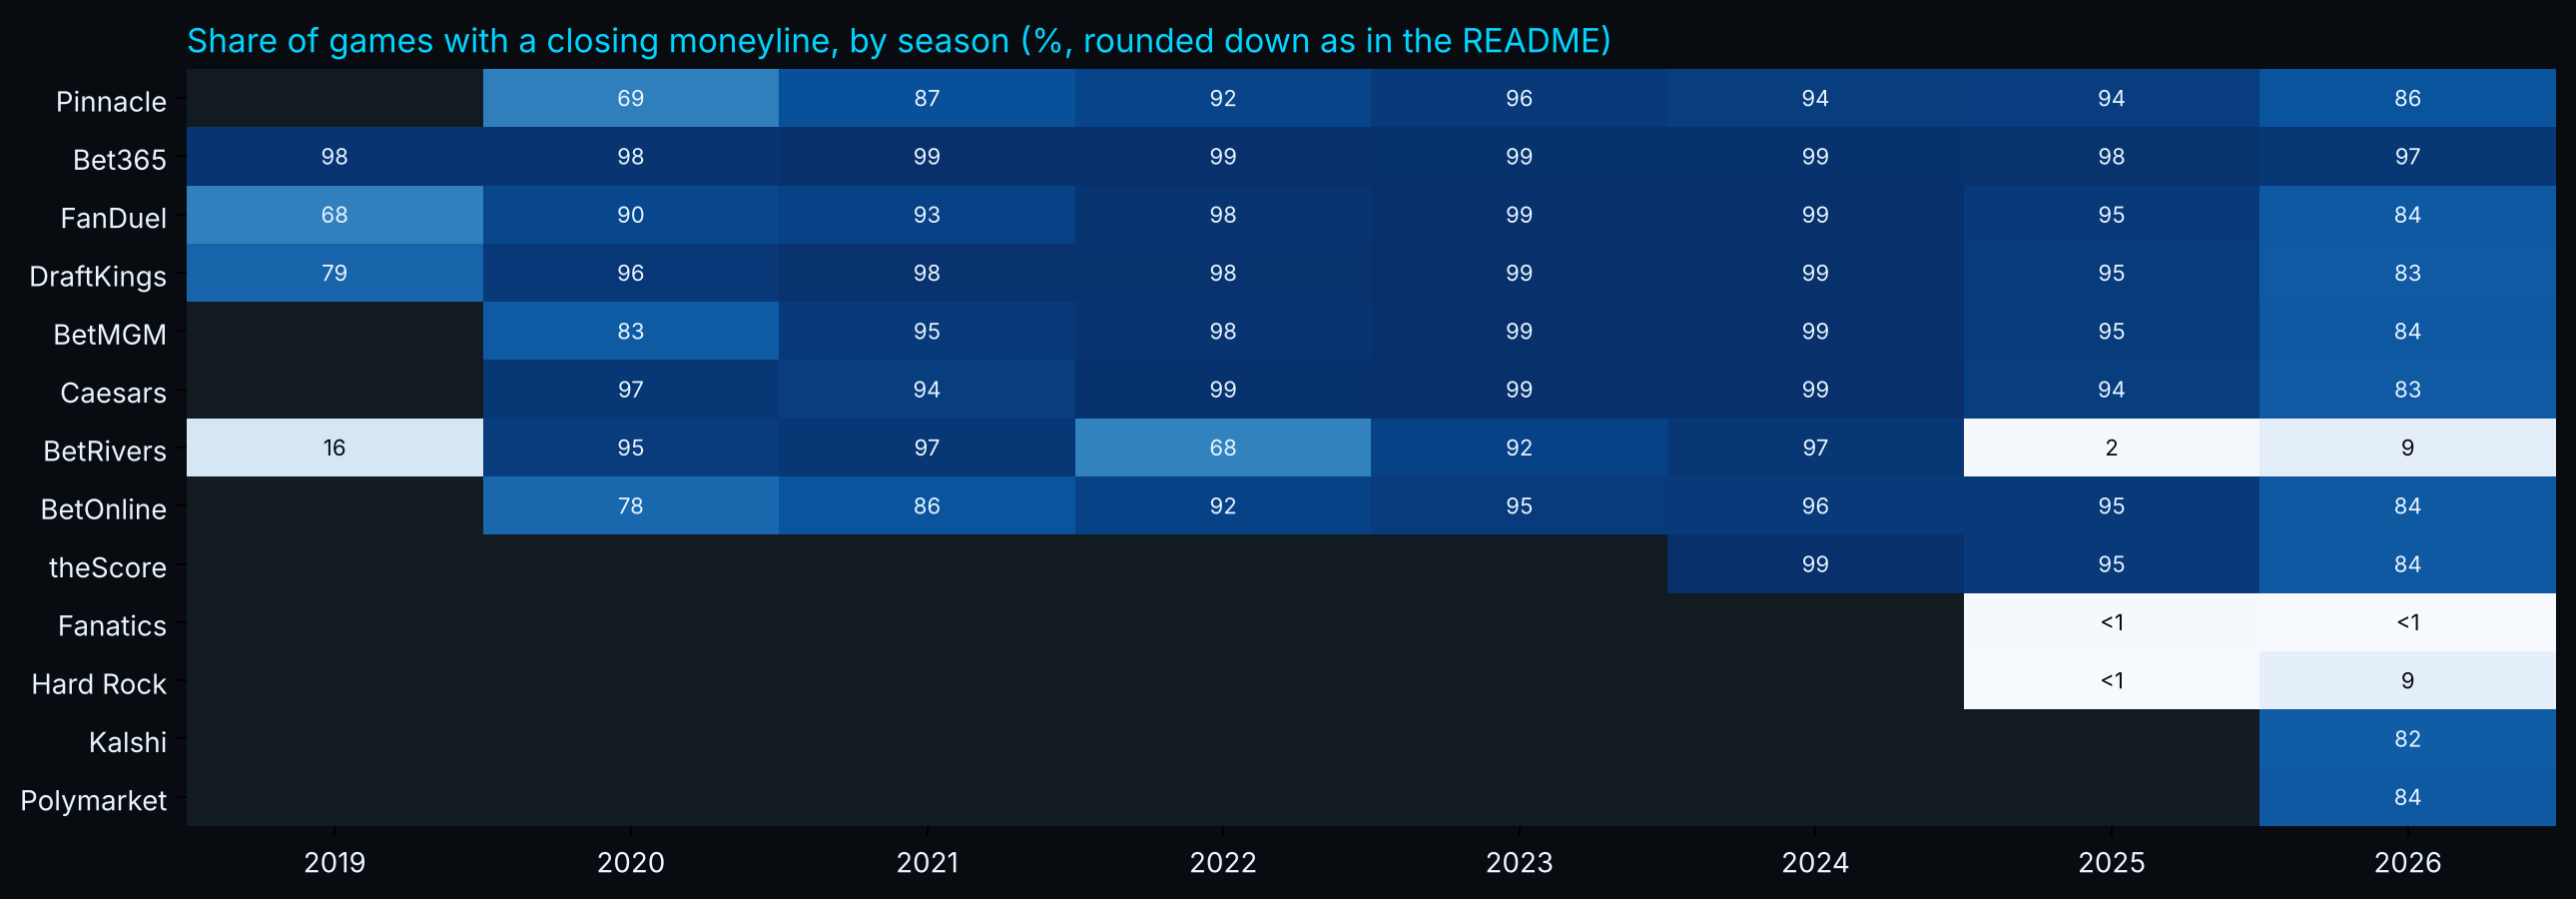

In [10]:
seasons = sorted(RAW["Season"].unique())
cov = pd.DataFrame({s: [100 * has(f"{s}_ML_Home_Close")[RAW["Season"] == se].mean() for se in seasons] for s in SOURCES}, index=seasons)
fig, ax = plt.subplots(figsize=(13, 4.6), facecolor="#080c10")
ax.set_facecolor("#080c10")
cmap = plt.get_cmap("Blues").copy(); cmap.set_bad("#121a22")
ax.imshow(np.ma.masked_equal(cov.T.values, 0), aspect="auto", cmap=cmap, vmin=0, vmax=100)
ax.set_xticks(range(len(cov.index)), cov.index, color="#e8f4ff")
ax.set_yticks(range(len(SOURCES)), [s.replace("HardRock", "Hard Rock") for s in SOURCES], color="#e8f4ff")
for i in range(len(SOURCES)):
    for j in range(len(cov.index)):
        v = cov.T.values[i, j]
        ax.text(j, i, "" if v == 0 else ("<1" if v < 1 else str(int(v))), ha="center", va="center", fontsize=8,
                color="#e8f4ff" if v > 55 else "#080c10")
ax.set_title("Share of games with a closing moneyline, by season (%, rounded down as in the README)", color="#00d4ff", loc="left")
for sp in ax.spines.values(): sp.set_visible(False)
plt.tight_layout(); plt.show()

## Result

In [11]:
n_ok = sum(ok for _, ok in RESULTS)
print(f"{n_ok} PASS / {len(RESULTS) - n_ok} FAIL out of {len(RESULTS)} checks")
assert n_ok == len(RESULTS), [l for l, ok in RESULTS if not ok]

82 PASS / 0 FAIL out of 82 checks


---
⚾ **[→ The full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/vjrnqv?utm_source=github&utm_medium=notebook&utm_campaign=mlb_us&utm_content=notebook_bottom)** · also on [Whop](https://whop.com/oliviersportsdata/mlb-opening-closing-odds-9-us-books-pinnacle-2019-2026/?utm_source=github&utm_medium=notebook&utm_campaign=mlb_us&utm_content=whop_bottom)

Licence: single commercial user. Use the data as you wish, including the models, predictions and products you sell.
Redistribution and resale of the files, or of the raw data in another format, are not permitted.
A question, an invoice or a custom extract: contact@oliviersportsdata.com

*Olivier Sports Data — From Chicken Area 🐔*